# Lab 2: predicting aqueous solubility end to end

**Goal.** Take the ESOL dataset from a raw CSV to a tuned, honestly evaluated model, using every
habit from Chapter 2: a reproducible split, a baseline, cross-validated hyperparameter search inside
a pipeline, a final held-out evaluation after model selection, a parity plot and an error analysis.

By the end you will have:

- a tidy table comparing a baseline, linear regression, ridge and k-nearest neighbours on the same test molecules;
- a parity plot of your best model;
- a list of the ten worst-predicted molecules and a hypothesis about *why* they are hard;
- a short written conclusion.

**How to work.** Run the notebook top to bottom. Cells marked `# TODO` are yours to complete.
The ✅ check cells after each task confirm that you are on track; they only use what the task asked for,
so if one fails, re-read the task. The computations run on a laptop CPU; no GPU is required. Local execution needs no account.
Google Colab requires a Google account, and a missing local ESOL file requires a download.

In [1]:
# Setup: works locally (course environment) and on Google Colab.
import importlib.util
import sys

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

missing = [p for p in ("numpy", "pandas", "matplotlib", "sklearn") if importlib.util.find_spec(p) is None]
if missing:
    pip_names = {"sklearn": "scikit-learn"}
    %pip install -q {" ".join(pip_names.get(p, p) for p in missing)}

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(f"Python {sys.version.split()[0]} | Colab: {IN_COLAB} | numpy {np.__version__} | pandas {pd.__version__}")

Python 3.12.14 | Colab: False | numpy 2.5.4 | pandas 3.1.0


## Data

ESOL (Delaney, 2004) lists 1,128 small organic molecules with their measured aqueous solubility,
`logS` in log10(mol/L), and five whole-molecule descriptors. The file is not bundled with the course
(its redistribution terms are unclear), so we try the local copy first and fall back to the canonical
download. The loading cell checks the SHA-256 checksum before parsing either source.
See `data/README.md` for the citation and checksum.

This repeats a deliberately simple random-split benchmark on a dataset explored in Chapter 1. It is
not a fresh blind assessment of choices informed by that exploration, nor a claim about unseen chemical
scaffolds. In a new project reserve evaluation data before target-guided EDA, and split related molecules
by the scientific unit that should be new at prediction time.

In [2]:
# Load the verified ESOL bytes, then parse the table.
import hashlib
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen

EXPECTED_SHA256 = "8c06a76f0c6487d29ab0f903e6a7a7139f189ab3c1178f159c8be8964602f189"
CANDIDATES = [
    "data/esol.csv", "../../../data/esol.csv",
    "https://raw.githubusercontent.com/Awguhst/MolModels/main/data/esol.csv",
    "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/delaney-processed.csv",
]
esol = None
for candidate in CANDIDATES:
    try:
        if candidate.startswith("https://"):
            with urlopen(candidate, timeout=30) as response:
                data_bytes = response.read()
        else:
            data_bytes = Path(candidate).read_bytes()
    except OSError:
        continue
    if hashlib.sha256(data_bytes).hexdigest() != EXPECTED_SHA256:
        raise ValueError(f"ESOL checksum mismatch: {candidate}. Check the source before continuing.")
    esol = pd.read_csv(BytesIO(data_bytes))
    print(f"Verified and loaded {len(esol)} molecules from {candidate}")
    break
if esol is None:
    raise RuntimeError("Could not load ESOL; check local paths or the download connection.")
esol.head(3)

Verified and loaded 1128 molecules from data/esol.csv


,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)


In [3]:
assert esol.shape == (1128, 10), f"expected 1128 rows and 10 columns, got {esol.shape}"
assert "measured log solubility in mols per litre" in esol.columns
print("✅ ESOL loaded: 1128 molecules, 10 columns")

✅ ESOL loaded: 1128 molecules, 10 columns


## Task 1: features and target

Define `X` as the five descriptors used in the chapter (`Molecular Weight`, `Number of H-Bond Donors`,
`Number of Rings`, `Number of Rotatable Bonds`, `Polar Surface Area`) and `y` as the measured logS.
For the main run, keep these five features fixed. As a separately planned development experiment,
you may include `Minimum Degree` as a sixth feature. Its low variation does not prove that it is useless;
compare feature sets with training CV, before opening a final test evaluation. Keep the column names in a list called `features` so that later cells can reuse it.

In [4]:
# Task 1: build X (descriptors) and y (measured logS)
features = [
    "Molecular Weight",
    "Number of H-Bond Donors",
    "Number of Rings",
    "Number of Rotatable Bonds",
    "Polar Surface Area",
]
target = "measured log solubility in mols per litre"

X = esol[features]
y = esol[target]
print(X.shape, y.shape)
X.describe().round(2)

(1128, 5) (1128,)


,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area
count,1128.00,1128.00,1128.00,1128.00,1128.00
mean,203.94,0.70,1.39,2.18,34.87
std,102.74,1.09,1.32,2.64,35.38
min,16.04,0.00,0.00,0.00,0.00
25%,121.18,0.00,0.00,0.00,0.00
50%,182.18,0.00,1.00,1.00,26.30
75%,270.37,1.00,2.00,3.00,55.44
max,780.95,11.00,8.00,23.00,268.68


In [5]:
assert X.shape[0] == 1128 and X.shape[1] in (5, 6), "X should have 1128 rows and 5 (or 6) descriptor columns"
assert y.shape == (1128,), "y should be a Series with one logS value per molecule"
assert abs(y.mean() - (-3.05)) < 0.05, "y does not look like measured logS (mean should be about -3.05)"
print("✅ Task 1: X and y defined")

✅ Task 1: X and y defined


## Task 2: split once, reproducibly

Split 80/20 with `train_test_split(..., test_size=0.2, random_state=42)`. Keep the test set untouched
until the final evaluation in Task 7. Every model choice comes from the training set; the later plots
diagnose the selected, frozen model without retuning it.

In [6]:
# Task 2: 80/20 split with random_state=42
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"train: {len(X_train)} molecules   test: {len(X_test)} molecules")

train: 902 molecules   test: 226 molecules


In [7]:
assert len(X_train) == 902 and len(X_test) == 226, "expected 902 training and 226 test molecules"
assert X_train.shape[0] == y_train.shape[0] and X_test.shape[0] == y_test.shape[0], "X and y sizes disagree: check the unpacking order"
assert X_test.index[0] == 1091, "the split does not match random_state=42 (did you shuffle differently?)"
print("✅ Task 2: 902 / 226 split, seed 42")

✅ Task 2: 902 / 226 split, seed 42


## Task 3: the baseline

Fit a `DummyRegressor(strategy="mean")` on the training set and write a function
`report(model, X, y)` that returns a dictionary with `MAE`, `RMSE` and `R2` (use
`mean_absolute_error`, `root_mean_squared_error`, `r2_score`). Save this helper for the final evaluation.

For now, estimate the baseline's RMSE on the training set using 5-fold cross-validation:
`cv = KFold(n_splits=5, shuffle=True, random_state=42)` and
`cross_val_score(..., cv=cv, scoring="neg_root_mean_squared_error")`.
Store the mean as `baseline_cv_rmse`. Reuse this same splitter for every model.

In [8]:
# Task 3: fit the mean baseline, define report(), and estimate baseline_cv_rmse on training data
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score


def report(model, X, y):
    """MAE, RMSE and R² of a fitted model on (X, y)."""
    pred = model.predict(X)
    return {
        "MAE": mean_absolute_error(y, pred),
        "RMSE": root_mean_squared_error(y, pred),
        "R2": r2_score(y, pred),
    }


cv = KFold(n_splits=5, shuffle=True, random_state=42)
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
baseline_cv_rmse = -cross_val_score(
    baseline, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error"
).mean()
print(f"baseline training CV RMSE: {baseline_cv_rmse:.3f} logS")

baseline training CV RMSE: 2.073 logS


In [9]:
assert hasattr(baseline, "constant_"), "baseline must be a fitted DummyRegressor"
assert np.isclose(baseline.constant_.item(), y_train.mean()), "fit the mean baseline on training targets only"
assert 2.0 < baseline_cv_rmse < 2.4, "baseline CV RMSE should be about 2.1 logS"
print(f"✅ Task 3: baseline training CV RMSE = {baseline_cv_rmse:.3f} logS")

✅ Task 3: baseline training CV RMSE = 2.073 logS


## Task 4: linear regression

Fit a plain `LinearRegression` on the training set. Also compute its 5-fold cross-validated RMSE on the
training set with `cross_val_score(..., cv=cv, scoring="neg_root_mean_squared_error")`, using
the same `cv` splitter defined in Task 3.
Store the fitted model as `linreg` and the mean CV RMSE as `linreg_cv_rmse`.

In [10]:
# Task 4: LinearRegression, fitted on train, plus its 5-fold CV RMSE
from sklearn.linear_model import LinearRegression
linreg = LinearRegression().fit(X_train, y_train)
linreg_cv_rmse = -cross_val_score(linreg, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error").mean()
print(f"linear regression: CV RMSE {linreg_cv_rmse:.3f} logS")

linear regression: CV RMSE 1.189 logS


In [11]:
assert hasattr(linreg, "coef_"), "linreg must be a fitted LinearRegression"
assert 1.1 < linreg_cv_rmse < 1.3, "CV RMSE of linear regression should be about 1.19 logS"
print("✅ Task 4: linear regression CV RMSE ≈ 1.19")

✅ Task 4: linear regression CV RMSE ≈ 1.19


## Task 5: ridge in a scaled pipeline, tuned by grid search

Build `make_pipeline(StandardScaler(), Ridge())` and tune `alpha` with `GridSearchCV` over
`[0.01, 0.1, 1, 10, 100, 1000]`, using the same `cv` and `scoring="neg_root_mean_squared_error"`.
Fit the search on the training set only. Store it as `ridge_search`. The pipeline parameter name is
`ridge__alpha` (step name, two underscores, parameter).

In [12]:
# Task 5: GridSearchCV over alpha for a StandardScaler + Ridge pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ridge_pipe = make_pipeline(StandardScaler(), Ridge())
ridge_search = GridSearchCV(
    ridge_pipe,
    {"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    cv=cv,
    scoring="neg_root_mean_squared_error",
).fit(X_train, y_train)

print("best alpha:", ridge_search.best_params_["ridge__alpha"])
print(f"best CV RMSE: {-ridge_search.best_score_:.3f} logS")
pd.DataFrame(ridge_search.cv_results_)[["param_ridge__alpha", "mean_test_score", "std_test_score"]].round(3)

best alpha: 10
best CV RMSE: 1.188 logS


,param_ridge__alpha,mean_test_score,std_test_score
0,0.01,-1.189,0.098
1,0.10,-1.189,0.098
2,1.00,-1.189,0.098
3,10.00,-1.188,0.098
4,100.00,-1.212,0.105
5,1000.00,-1.535,0.122


In [13]:
assert hasattr(ridge_search, "best_params_"), "ridge_search must be a fitted GridSearchCV"
assert "ridge__alpha" in ridge_search.best_params_, "the grid must be over ridge__alpha"
assert 1.1 < -ridge_search.best_score_ < 1.3, "best CV RMSE for ridge should be about 1.19 logS"
print(f"✅ Task 5: ridge tuned, best alpha = {ridge_search.best_params_['ridge__alpha']}")

✅ Task 5: ridge tuned, best alpha = 10


Read the full alpha table. In the reference run, small penalties perform similarly to plain linear
regression and large penalties hurt. This suggests limited benefit from ridge within this search and
feature set; sample count alone does not establish that overfitting is absent. `best_score_` selected
alpha and is not an independent estimate of the selected model’s performance.

## Task 6: k-nearest neighbours, tuned the same way

Build `make_pipeline(StandardScaler(), KNeighborsRegressor())` and tune `n_neighbors` over
`[1, 3, 5, 7, 11, 15, 21]` with the same `cv` and scoring. Store the search as `knn_search`.
Explain why scaling changes both models: it changes distance contributions for kNN and the relative
coefficient penalties for ridge. Neither model should silently privilege a feature just because its
measurement unit produces larger numbers.

In [14]:
# Task 6: GridSearchCV over n_neighbors for a StandardScaler + KNeighborsRegressor pipeline
from sklearn.neighbors import KNeighborsRegressor

knn_pipe = make_pipeline(StandardScaler(), KNeighborsRegressor())
knn_search = GridSearchCV(
    knn_pipe,
    {"kneighborsregressor__n_neighbors": [1, 3, 5, 7, 11, 15, 21]},
    cv=cv,
    scoring="neg_root_mean_squared_error",
).fit(X_train, y_train)

print("best k:", knn_search.best_params_["kneighborsregressor__n_neighbors"])
print(f"best CV RMSE: {-knn_search.best_score_:.3f} logS")
pd.DataFrame(knn_search.cv_results_)[["param_kneighborsregressor__n_neighbors", "mean_test_score", "std_test_score"]].round(3)

best k: 7
best CV RMSE: 0.943 logS


,param_kneighborsregressor__n_neighbors,mean_test_score,std_test_score
0,1,-1.073,0.081
1,3,-0.949,0.077
2,5,-0.948,0.086
3,7,-0.943,0.086
4,11,-0.960,0.094
5,15,-0.990,0.094
6,21,-1.041,0.116


In [15]:
assert hasattr(knn_search, "best_params_"), "knn_search must be a fitted GridSearchCV"
assert "kneighborsregressor__n_neighbors" in knn_search.best_params_, "tune kneighborsregressor__n_neighbors"
assert -knn_search.best_score_ < 1.0, "a scaled kNN should reach a CV RMSE below 1.0 logS (did you include the StandardScaler?)"
print(f"✅ Task 6: kNN tuned, best k = {knn_search.best_params_['kneighborsregressor__n_neighbors']}")

✅ Task 6: kNN tuned, best k = 7


## Task 7: select by cross-validation, then evaluate on the test set

First collect the fitted models and their mean CV RMSE on the training set. Choose `best_name` and
`best_model` using only the lowest CV RMSE. Freeze that choice before looking at any test scores.

Then collect, for each of the four models (baseline, linear, ridge, kNN), the test MAE, RMSE and R².
Build a DataFrame `results` with one row per model and the columns `CV RMSE`, `test MAE`, `test RMSE`,
`test R2`. These are the final held-out results, not another model-selection step. Report the selected model
even if another candidate happens to have a better test score; the additional rows are predeclared
comparisons. A second search after viewing this table would need new evaluation data.
`GridSearchCV` refits the best pipeline on the full training set, so `ridge_search` and `knn_search`
can be used directly as models.

In [16]:
# Task 7: choose best_name / best_model by training CV RMSE, then build the final test results table

models = {
    "baseline (mean)": (baseline, baseline_cv_rmse),
    "linear regression": (linreg, linreg_cv_rmse),
    "ridge (scaled, tuned)": (ridge_search, -ridge_search.best_score_),
    "kNN (scaled, tuned)": (knn_search, -knn_search.best_score_),
}

# Freeze the model choice before evaluating any held-out targets.
best_name = min(models, key=lambda name: models[name][1])
best_model = models[best_name][0]

rows = []
for name, (model, cv_rmse) in models.items():
    scores = report(model, X_test, y_test)
    rows.append({"model": name, "CV RMSE": cv_rmse, "test MAE": scores["MAE"],
                 "test RMSE": scores["RMSE"], "test R2": scores["R2"]})

results = pd.DataFrame(rows).set_index("model")
results.round(3)

,CV RMSE,test MAE,test RMSE,test R2
model,,,,
baseline (mean),2.073,1.732,2.174,-0.000
linear regression,1.189,0.904,1.212,0.689
"ridge (scaled, tuned)",1.188,0.905,1.214,0.688
"kNN (scaled, tuned)",0.943,0.679,0.912,0.824


In [17]:
assert list(results.columns) == ["CV RMSE", "test MAE", "test RMSE", "test R2"], "check the results column names"
assert best_name == results["CV RMSE"].idxmin(), "select using training CV RMSE, never test scores"
assert len(results) == 4, "one row per predeclared model: baseline, linear, ridge, kNN"
assert np.isfinite(results.to_numpy()).all(), "every reported score must be finite"
assert (results[["CV RMSE", "test MAE", "test RMSE"]] >= 0).all().all(), "error metrics cannot be negative"
print("✅ Task 7: final table complete; model choice came from training CV")

✅ Task 7: final table complete; model choice came from training CV


Read the table in two directions. Down the columns, compare the already selected model with the
mean baseline. Across the rows, compare the development CV and test errors without requiring them
to agree. Different cases, training sizes and selection optimism can create a gap. A surprisingly good
test score can also reflect leakage or an easier sample; agreement by itself proves neither honesty nor
independence. Keep the choice made before test evaluation even if the test ranking differs.

## Task 8: parity plot of the selected model

Use `best_model`, already selected by training CV in Task 7. Store its test predictions in `pred_best`
and draw a parity plot: measured logS on the x axis, predicted on the y axis, with the diagonal
`y = x`. Label the axes with units.

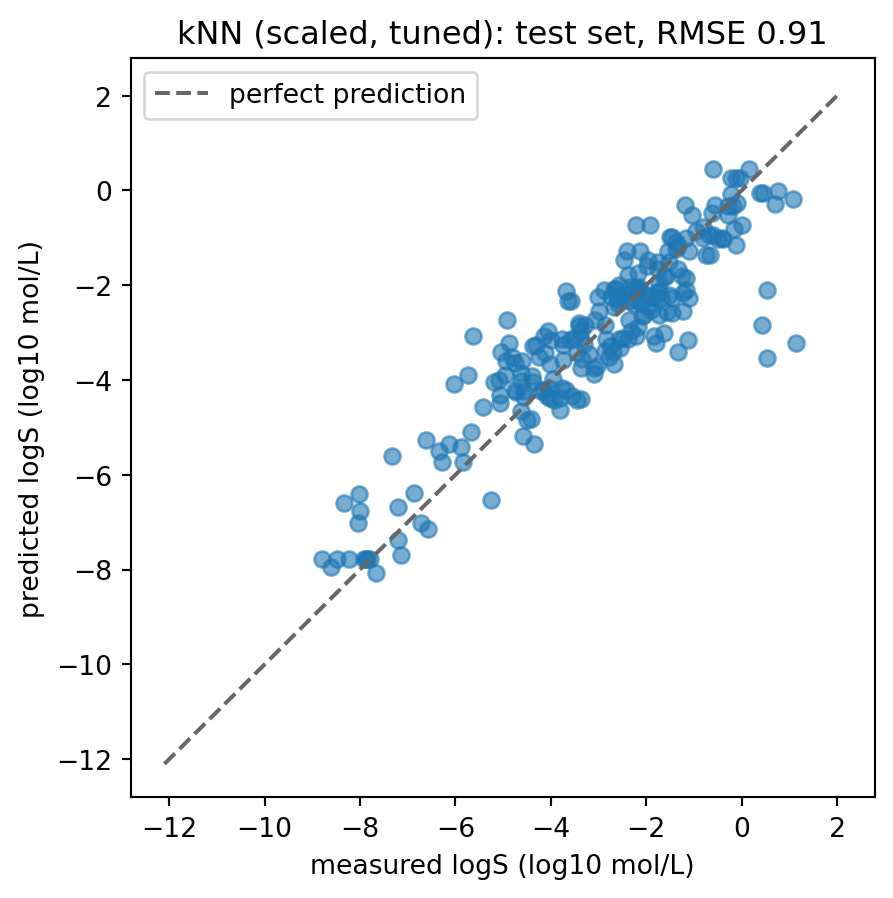

In [18]:
#| fig-alt: "Parity plot of predicted against measured logS for the test molecules using the model selected by training cross-validation, with a dashed diagonal for perfect prediction; points scatter around the diagonal and spread more at the insoluble end."
# Task 8: parity plot (measured vs predicted logS) for the model already selected by training CV
pred_best = best_model.predict(X_test)

fig, ax = plt.subplots(figsize=(5, 5))
lims = [y.min() - 0.5, y.max() + 0.5]
ax.scatter(y_test, pred_best, alpha=0.6)
ax.plot(lims, lims, linestyle="--", color="0.4", label="perfect prediction")
ax.set(xlabel="measured logS (log10 mol/L)", ylabel="predicted logS (log10 mol/L)",
       title=f"{best_name}: test set, RMSE {results.loc[best_name, 'test RMSE']:.2f}")
ax.legend()
plt.show()

In [19]:
assert len(pred_best) == len(y_test), "pred_best must have one prediction per test molecule"
assert np.allclose(pred_best, best_model.predict(X_test)), "use the model selected before test evaluation"
assert np.isfinite(pred_best).all(), "predictions must be finite"
print(f"✅ Task 8: plotted the preselected model '{best_name}'")

✅ Task 8: plotted the preselected model 'kNN (scaled, tuned)'


## Task 9: the ten worst-predicted molecules

Build a DataFrame `worst` with the columns `Compound ID`, `smiles`, `measured`, `predicted` and
`residual` (measured − predicted) for the test molecules, sorted by absolute residual, and keep the
ten largest. Inspect the compound names and SMILES (structure interpretation is developed in Chapter 5).
Separate what you can observe from a hypothesis: do some structures share patterns not explicitly
encoded by these descriptors? Also consider measurement conditions or unusual input values.

In [20]:
# Task 9: the 10 test molecules with the largest absolute residual, with names and SMILES
worst = (
    esol.loc[X_test.index, ["Compound ID", "smiles"]]
    .assign(measured=y_test, predicted=pred_best, residual=y_test - pred_best)
    .sort_values("residual", key=np.abs, ascending=False)
    .head(10)
)
worst.round(2)

,Compound ID,smiles,measured,predicted,residual
1064,vamidothion,CNC(=O)C(C)SCCSP(=O)(OC)(OC),1.14,-3.22,4.37
292,Dimecron,CCN(CC)C(=O)C(=CCOP(=O)(OC)OC)Cl,0.52,-3.53,4.05
796,Triethyl phosphate,CCOP(=O)(OCC)OCC,0.43,-2.83,3.26
758,Acephate,COP(=O)(NC(C)=O)SC,0.54,-2.10,2.64
96,Chlorothalonil,c1(C#N)c(Cl)c(C#N)c(Cl)c(Cl)c(Cl)1,-5.64,-3.06,-2.58
548,"Hexachloro-1,3-butadiene",ClC(=C(Cl)C(=C(Cl)Cl)Cl)Cl,-4.92,-2.74,-2.18
436,Diethyl sulfide,CCSCC,-1.34,-3.41,2.07
174,cycloheximide,CC1CC(C)C(=O)C(C1)C(O)CC2CC(=O)NC(=O)C2,-1.13,-3.16,2.03
963,difluron,Fc1cccc(F)c1C(=O)NC(=O)Nc2ccc(Cl)cc2,-6.02,-4.09,-1.93
218,Carbophenthion,CCOP(=S)(OCC)SCSc1ccc(Cl)cc1,-5.74,-3.90,-1.83


In [21]:
assert len(worst) == 10, "keep exactly the ten worst molecules"
assert {"Compound ID", "smiles", "measured", "predicted", "residual"} <= set(worst.columns), "missing columns"
assert worst["residual"].abs().is_monotonic_decreasing, "sort by absolute residual, largest first"
print("✅ Task 9: worst-ten table built; now read the SMILES")

✅ Task 9: worst-ten table built; now read the SMILES


The worst-ten table identifies cases for investigation; it does not establish why the model missed
them. Inspect molecular identity, recorded units and available measurement context before assigning a
chemical explanation. These five aggregate descriptors do not explicitly encode every functional group
or substitution pattern, although they can reflect some of their effects. A new representation is a
hypothesis to test during a new development cycle, not a guaranteed fix for the errors just inspected.

## Task 10: conclusion

Complete the template below with your own numbers and observations (three to six sentences).

> **Conclusion.** Training cross-validation selected [fill in] with settings [fill in]. On the reserved set of [fill in]
> molecules, its RMSE was [fill in] logS (MAE [fill in], R² [fill in]), compared with [fill in] for the mean baseline.
> Its CV RMSE was [fill in]; the difference from the test result was [fill in]. The error table suggests investigating
> [fill in], but does not establish the cause. This random split assesses [fill in] and does not establish [fill in].
> A next development experiment would be [fill in], evaluated with [fill in].


**Example conclusion (reference run, five descriptors).** Training cross-validation selected scaled
k-nearest neighbours with $k=7$. On 226 reserved molecules its RMSE was about 0.91 logS (MAE 0.68,
R² 0.82), compared with a baseline RMSE of 2.17. The learned models' CV and test RMSEs differ by about
0.03 logS or less in this run; that agreement is descriptive, not proof against leakage. Some large
errors involve organophosphorus or halogenated compounds, suggesting that explicit structural features
and measurement context deserve investigation. A new development experiment could compare a logP
feature or fingerprints using a scaffold-aware evaluation, because this random split does not establish
performance on a new chemical series. Use your own computed values if your declared feature set differs.


## Optional extension (★★★): soluble or not?

Many projects need a yes/no answer rather than a number. Define "soluble" as logS > −3 (a teaching
cut-off for this exercise, not a universal definition), build a scaled `LogisticRegression`
pipeline on the same train/test split, and evaluate it with a confusion matrix, accuracy, and a ROC
curve with its AUC. Compare the accuracy with a `DummyClassifier(strategy="most_frequent")` baseline. The positive
class is 1 (soluble); changing the solubility cut-off or the probability decision threshold is a new
modelling decision. This extension reuses inspected cases as a teaching exercise, so it is not a new
untouched evaluation; use separate validation data for any further choices.

In [22]:
# Extension: classify soluble (logS > -3) vs insoluble with a scaled LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score

y_train_cls = (y_train > -3).astype(int)
y_test_cls = (y_test > -3).astype(int)

clf_baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train_cls)
clf = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train_cls)

auc = roc_auc_score(y_test_cls, clf.predict_proba(X_test)[:, 1])
print(f"soluble fraction (train): {y_train_cls.mean():.2f}")
print(f"baseline accuracy: {clf_baseline.score(X_test, y_test_cls):.3f}")
print(f"logistic accuracy: {clf.score(X_test, y_test_cls):.3f}   ROC AUC: {auc:.3f}")

soluble fraction (train): 0.51
baseline accuracy: 0.544
logistic accuracy: 0.885   ROC AUC: 0.933


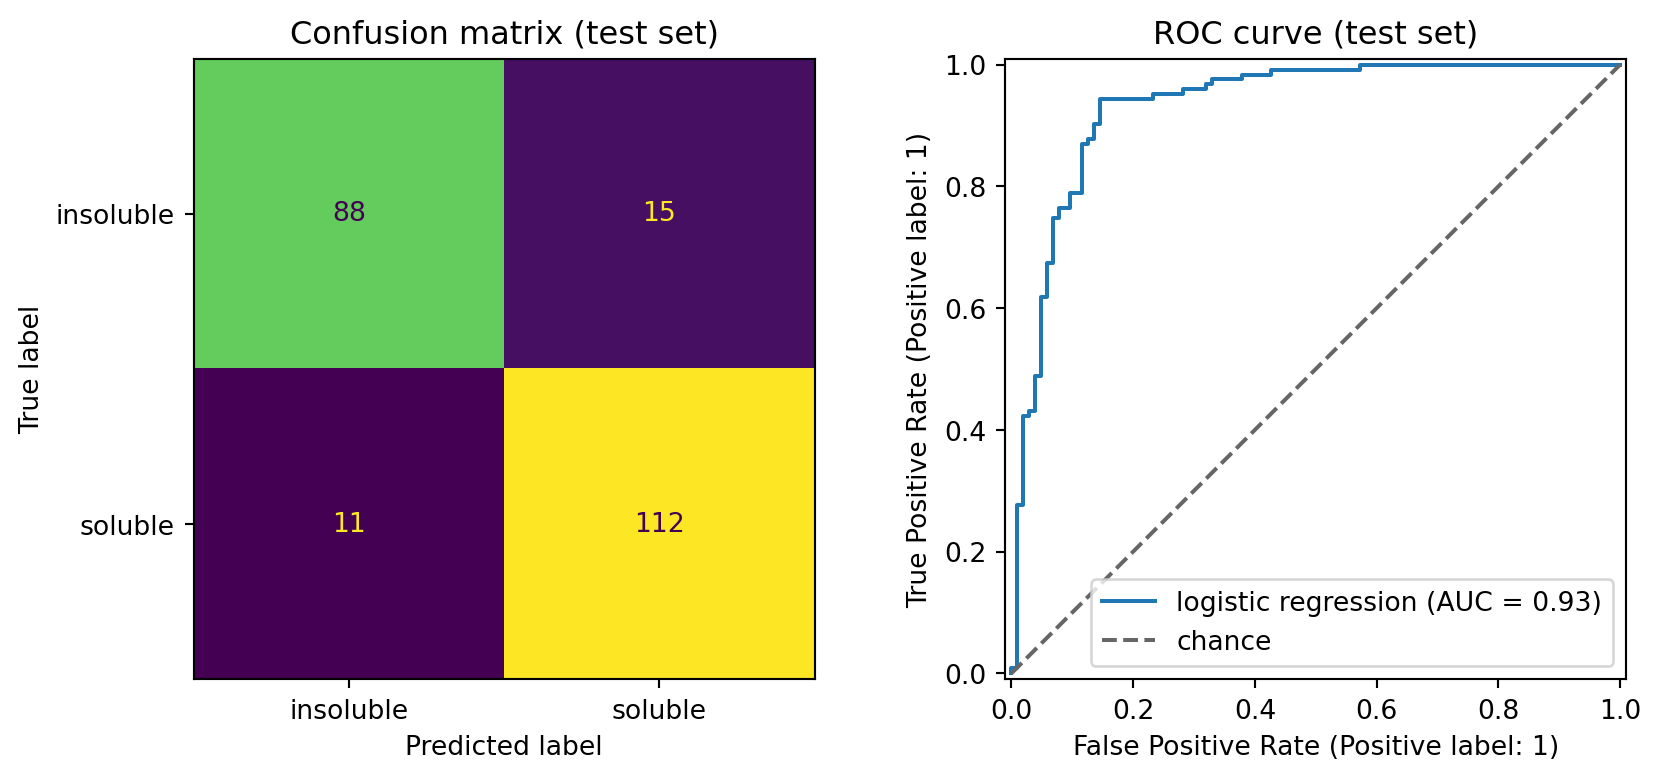

In [23]:
#| fig-alt: "Two panels: a two-by-two confusion matrix for the soluble/insoluble classifier on the test set, and its ROC curve rising towards the top-left corner with a dashed diagonal for a random classifier."
# Extension: confusion matrix and ROC curve side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test_cls, display_labels=["insoluble", "soluble"], ax=ax1, colorbar=False)
ax1.set(title="Confusion matrix (test set)")
RocCurveDisplay.from_estimator(clf, X_test, y_test_cls, ax=ax2, name="logistic regression")
ax2.plot([0, 1], [0, 1], linestyle="--", color="0.4", label="chance")
ax2.set(title="ROC curve (test set)")
ax2.legend(loc="lower right")
plt.show()

In [24]:
assert hasattr(clf, "predict_proba"), "clf must be a fitted classifier pipeline"
assert clf.score(X_test, y_test_cls) > 0.8, "logistic regression should reach well over 80% accuracy"
assert auc > 0.85, "ROC AUC should be above 0.85"
print("✅ Extension: classifier beats the majority-class baseline")

✅ Extension: classifier beats the majority-class baseline


The classes are nearly balanced at this cut-off (about half of the molecules are "soluble"), so the
majority baseline is only about 54% and the logistic model's ~88% accuracy and AUC of about 0.93 are an improvement on this particular teaching split. Look at the confusion matrix: are the mistakes symmetric, or does the model prefer one kind
of error? If this were a screening cascade, which error would be more expensive?

## Reflection questions

1. Suppose the test RMSE is lower than the CV RMSE. Give one legitimate explanation and one workflow
   error that could produce this. Why can agreement between the two scores not prove there is no leakage?
2. kNN beat the linear models comfortably. Episode 2.6 showed that kNN is also the model most helped
   by duplicates and near-duplicates across the split. How would you check whether ESOL's test set
   contains close analogues of training molecules, and what split would you use to find out how the
   model does on genuinely new chemistry?
3. Propose two new features (or one new representation) motivated by the error analysis. State what
   you hypothesise each might improve and how you would test that without selecting improvements on
   the already inspected test set. What else besides missing features could explain a large residual?